# Getting started with NLP: teaching a model to compare patent phrases

## What are we building?
A model that reads **two short phrases from patents** and says **how similar their meaning is**, as a number from 0 to 1.

| anchor | target | context | score |
|---|---|---|---|
| abatement | abatement of pollution | A47 | 0.50 |
| abatement | act of abating | A47 | 0.75 |
| abatement | active catalyst | A47 | 0.25 |

- `anchor` and `target` are the two phrases we compare.
- `context` is a code for the *technology area* of the patent (for example `A47` = furniture). The same pair of words can mean different things in different areas, which is why the model must see it.
- `score` is how similar a human expert judged them: `0` = unrelated, `0.25` = somewhat related, `0.5` = synonym with a different part of speech, `0.75` = close synonym, `1` = identical meaning.

The data comes from the Kaggle competition **U.S. Patent Phrase to Phrase Matching**. This notebook follows Jeremy Howard's *"Getting started with NLP for absolute beginners"*, rebuilt to run locally on Windows with a GPU.

## Why are we building it?
This is **Step 3** of the deep-learning roadmap (NLP and fine-tuning pretrained Hugging Face models). It teaches the full recipe that most modern NLP work uses:

1. **Turn a problem into text.** Our data is a table (three columns), not a paragraph. We will glue the columns into one sentence so a *language model* can read it. This trick works for many problems that do not look like language at first.
2. **Tokenization.** A neural network only understands numbers, so we learn how text is chopped into pieces and turned into numbers.
3. **Fine-tuning a pretrained model.** Training a language model from nothing costs a fortune. Instead we start from **DeBERTa**, a model that already understands English, and adapt it to our task with a small dataset. This is *transfer learning*.
4. **A proper validation set and a proper metric.** Why we keep some data hidden, why the way we split it matters a lot here, and why we use **Pearson correlation** instead of accuracy.
5. **The bridge to RAG and search.** Scoring "how well do these two texts match?" is exactly what a *reranker* does in a retrieval system. You are building a small one.

> **Same ideas as the Titanic notebooks, new kind of data.** You will see the same loop again: look at the data, prepare it, split off a validation set, train, check a metric, predict on the test set.

## 1. Setup

### Where is the data?
Same pattern as the Titanic notebooks: on Kaggle's servers the data is already provided; on your own computer we download it once with the Kaggle API and reuse it. (The Kaggle account must have accepted the competition rules, otherwise the download is refused.)

In [1]:
from pathlib import Path   # Path builds file paths that work on any operating system
import os                  # os lets us read environment variables

# Kaggle's servers set this variable; on your own computer it is empty ('')
iskaggle = os.environ.get('KAGGLE_KERNEL_RUN_TYPE', '')

if iskaggle:
    path = Path('../input/us-patent-phrase-to-phrase-matching')   # already provided on Kaggle
else:
    path = Path('us-patent')               # a folder named 'us-patent' next to this notebook
    if not (path/'train.csv').exists():    # only download if we don't have it yet
        import zipfile, kaggle
        kaggle.api.competition_download_cli('us-patent-phrase-to-phrase-matching', path=str(path))
        zipfile.ZipFile(path/'us-patent-phrase-to-phrase-matching.zip').extractall(path)

path   # show which folder we will read from

WindowsPath('us-patent')

### Imports and a repeatable setup

| Import | What it gives us |
|---|---|
| `numpy` (`np`) | fast arrays and maths |
| `pandas` (`pd`) | tables (`DataFrame`) |
| `torch` | PyTorch, the engine underneath everything |
| `datasets.Dataset` | Hugging Face's table type for training data (fast and memory-friendly) |
| `AutoTokenizer`, `AutoModelForSequenceClassification` | download a pretrained **tokenizer** and **model** by name |
| `TrainingArguments`, `Trainer` | the settings and the ready-made training loop (the loop you wrote by hand in `pytorch_from_scratch.ipynb`) |

`set_seed(42)` fixes the random number generators (Python, numpy and PyTorch) so that results are similar every time you run the notebook. 42 is an arbitrary choice.

In [2]:
import numpy as np                    # arrays and maths
import pandas as pd                   # tables
import torch                          # PyTorch
from datasets import Dataset, DatasetDict      # Hugging Face tables
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, set_seed)

pd.options.display.float_format = '{:.2f}'.format   # show floats with 2 decimals
set_seed(42)                                         # make random choices repeatable

c:\Users\Pranav\Documents\andrew-ng-ml-course\foundations\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Do we have a GPU?
Training a transformer on a CPU is painfully slow; a GPU does the same work many times faster. This cell tells us what PyTorch can see. You should see your RTX 4050. If it says `cpu`, the notebook still runs but training will take much longer.

In [3]:
print('PyTorch version:', torch.__version__)
print('GPU available  :', torch.cuda.is_available())      # True if PyTorch can use the graphics card
if torch.cuda.is_available():
    print('GPU name       :', torch.cuda.get_device_name(0))
    print('GPU memory     : %.1f GB' % (torch.cuda.get_device_properties(0).total_memory / 1e9))

PyTorch version: 2.14.1+cu130
GPU available  : True
GPU name       : NVIDIA GeForce RTX 4050 Laptop GPU
GPU memory     : 6.4 GB


## 2. Look at the data

### Load it
`train.csv` has the human scores (we learn from it); `test.csv` has no scores (we must predict them). The test set here is tiny (just 36 rows) because Kaggle keeps the real test data hidden.

In [4]:
df = pd.read_csv(path/'train.csv')        # training rows: we know the human score
tst_df = pd.read_csv(path/'test.csv')     # test rows: we have to predict the score
df.head()                                 # the first 5 rows

,id,anchor,target,context,score
0,37d61fd2272659b1,abatement,abatement of pollution,A47,0.50
1,7b9652b17b68b7a4,abatement,act of abating,A47,0.75
2,36d72442aefd8232,abatement,active catalyst,A47,0.25
3,5296b0c19e1ce60e,abatement,eliminating process,A47,0.50
4,54c1e3b9184cb5b6,abatement,forest region,A47,0.00


In [5]:
# describe(include='object') summarises the text columns: how many rows, how many different values,
# and which value is the most common ("top") and how often ("freq")
df.describe(include='object')

C:\Users\Pranav\AppData\Local\Temp\ipykernel_21388\3261156043.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,id,anchor,target,context
count,36473,36473,36473,36473
unique,36473,733,29340,106
top,37d61fd2272659b1,component composite coating,composition,H01
freq,1,152,24,2186


What this tells us:

- There are about **36,000 rows** but only **733 different anchors**. Each anchor appears many times, paired with many different targets. Remember this: it matters when we split the data later.
- There are **106 contexts** (technology areas).
- The `target` column has far more variety than `anchor`.

### What do the scores look like?
The scores come in only 5 values. Let's count how many rows have each one.

In [6]:
# value_counts() counts how many times each value appears; sort_index() lists them in order
df.score.value_counts().sort_index()

score
0.00     7471
0.25    11519
0.50    12300
0.75     4029
1.00     1154
Name: count, dtype: int64

<Axes: >

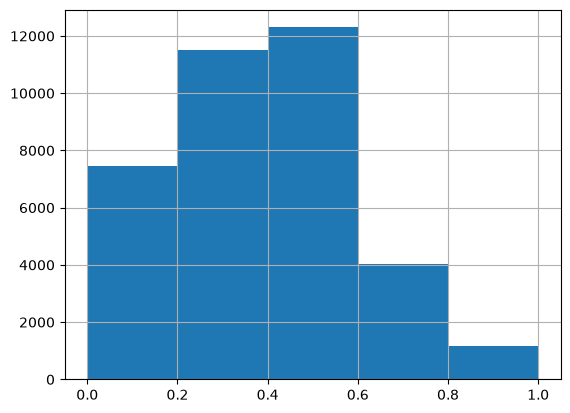

In [7]:
df.score.hist(bins=5)   # a bar chart of the same counts

Most pairs are only slightly related (0.25 and 0.5). Very few are true matches (1.0). This is typical of a search problem: most candidates are *not* good matches.

### Look at one anchor
All the rows for the anchor `"abatement"` with context `A47`. The model has to learn that "abatement of pollution" and "act of abating" are similar to "abatement", and "active catalyst" is not.

In [8]:
# df.anchor == 'abatement' is True/False for every row; df[...] keeps only the True rows
df[(df.anchor == 'abatement') & (df.context == 'A47')].head(8)

,id,anchor,target,context,score
0,37d61fd2272659b1,abatement,abatement of pollution,A47,0.50
1,7b9652b17b68b7a4,abatement,act of abating,A47,0.75
2,36d72442aefd8232,abatement,active catalyst,A47,0.25
3,5296b0c19e1ce60e,abatement,eliminating process,A47,0.50
4,54c1e3b9184cb5b6,abatement,forest region,A47,0.00
5,067203128142739c,abatement,greenhouse gases,A47,0.25
6,061d17f04be2d1cf,abatement,increased rate,A47,0.25
7,e1f44e48399a2027,abatement,measurement level,A47,0.25


## 3. Turn the table into text

A language model reads **one string of text**. We have three columns, so we **glue them into one sentence**, with labels so the model can tell the parts apart:

```
TEXT1: A47; TEXT2: abatement of pollution; ANC1: abatement
```

- `TEXT1` is the context, `TEXT2` is the target phrase, `ANC1` is the anchor phrase. The names are arbitrary. They are just markers.
- We are *not* teaching the model anything about patents by hand. We give it the raw ingredients and let fine-tuning work out how they relate.

This is the key idea of the lesson: **if you can express your problem as text, you can use a pretrained language model.**

The `+` operator joins strings, and pandas lets us do it for a whole column at once.

In [9]:
def make_input(d):
    # Build one string per row by joining the three columns with labels in between
    d['input'] = 'TEXT1: ' + d.context + '; TEXT2: ' + d.target + '; ANC1: ' + d.anchor
    return d

df = make_input(df)           # add an 'input' column to the training data
tst_df = make_input(tst_df)   # and to the test data, exactly the same way
df.input.head(3).tolist()     # look at three examples

['TEXT1: A47; TEXT2: abatement of pollution; ANC1: abatement',
 'TEXT1: A47; TEXT2: act of abating; ANC1: abatement',
 'TEXT1: A47; TEXT2: active catalyst; ANC1: abatement']

## 4. Tokenization: from text to numbers

A neural network can only do maths on numbers, so we have to convert the text. This takes two steps:

1. **Tokenization**: split the text into pieces called **tokens**.
2. **Numericalization**: look each token up in a fixed **vocabulary** (a big list) and replace it with its position number (its **ID**).

### Why not just split into words?
Words are a poor unit: a vocabulary of all English words is huge, and any word the model has never seen would be unknown. Splitting into single letters is the other extreme: no unknown words, but the sequences become very long and each piece carries little meaning.

**Subword tokenization** is the middle path: common words stay whole, rare words are split into smaller known pieces. That is what modern models use.

### Which tokenizer?
A pretrained model was trained with **one specific tokenizer**, and we must use exactly the same one. Using a different tokenizer would give different numbers, and the model's learned knowledge would be looked up in the wrong places. Hugging Face makes this easy: the same model name loads both the model and its matching tokenizer.

We use **`microsoft/deberta-v3-small`**: a small, fast, strong model that is good at understanding text, and small enough to train quickly on a laptop GPU.

In [10]:
model_nm = 'microsoft/deberta-v3-small'      # the pretrained model we will adapt (downloaded on first use)
tokz = AutoTokenizer.from_pretrained(model_nm)   # the matching tokenizer

### Try the tokenizer
`tokenize` shows the pieces. The `▁` symbol marks "this piece starts a new word" (it replaces the space). Notice how a rare word is split into smaller pieces, while common words stay whole.

In [11]:
print(tokz.tokenize("G'day folks, I'm Jeremy from fast.ai!"))    # an everyday sentence
print(tokz.tokenize("A platypus is an ornithorhynchus anatinus."))   # a rare word gets chopped up

['▁G', "'", 'day', '▁folks', ',', '▁I', "'", 'm', '▁Jeremy', '▁from', '▁fast', '.', 'ai', '!']
['▁A', '▁platypus', '▁is', '▁an', '▁or', 'ni', 'tho', 'rhynch', 'us', '▁an', 'at', 'inus', '.']


In [12]:
# Now a real example from our data
sample = df.input.iloc[0]
print(sample)
print(tokz.tokenize(sample))

TEXT1: A47; TEXT2: abatement of pollution; ANC1: abatement
['▁TEXT', '1', ':', '▁A', '47', ';', '▁TEXT', '2', ':', '▁abatement', '▁of', '▁pollution', ';', '▁ANC', '1', ':', '▁abatement']


### Numericalize
Calling the tokenizer directly does everything at once: it splits the text, adds special start/end tokens, and returns the numbers. The result has two parts:

- `input_ids`: the token IDs (the numbers the model will read).
- `attention_mask`: `1` for real tokens and `0` for padding. Padding is dummy filler that makes all texts in a batch the same length; the mask tells the model to ignore it.

In [13]:
enc = tokz(sample)          # tokenize AND numericalize in one call
enc['input_ids']            # the numbers the model will see

[1,
 54453,
 435,
 294,
 336,
 5753,
 346,
 54453,
 445,
 294,
 47284,
 265,
 6435,
 346,
 23702,
 435,
 294,
 47284,
 2]

In [14]:
# Decode turns the numbers back into text, so we can check nothing went wrong.
# [CLS] marks the start of the text and [SEP] the end: special tokens the model expects.
tokz.decode(enc['input_ids'])

'[CLS] TEXT1: A47; TEXT2: abatement of pollution; ANC1: abatement[SEP]'

### Tokenize the whole dataset
We wrap the tokenizer in a small function and let the Hugging Face `Dataset` apply it to **every row at once** with `.map(..., batched=True)`. `batched=True` processes many rows per call, which is much faster.

We do **not** pad here. The training code (the *data collator*) pads each batch only to the length of its own longest example, which is faster than padding everything to the same huge length. Our texts are short, so this works well.

### The label column
The `Trainer` looks for the thing we want to predict in a column called **`labels`**. Ours is called `score`, so we rename it. (It must be a float, because we are predicting a number, not choosing a category.)

In [15]:
ds = Dataset.from_pandas(df[['input', 'score', 'anchor']])   # pandas table -> Hugging Face table (keep anchor for the split)

def tok_func(batch):
    # batch['input'] is a list of strings; the tokenizer returns input_ids etc. for all of them
    return tokz(batch['input'])

ds = ds.map(tok_func, batched=True)           # add tokens to every row
ds = ds.rename_column('score', 'labels')      # the Trainer expects the target in a column named 'labels'
ds

Map: 100%|██████████| 36473/36473 [00:00<00:00, 46982.38 examples/s]


Dataset({
    features: ['input', 'labels', 'anchor', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 36473
})

In [16]:
ds[0]    # one finished training example: text, label, anchor, input_ids, attention_mask (and token_type_ids)

{'input': 'TEXT1: A47; TEXT2: abatement of pollution; ANC1: abatement',
 'labels': 0.5,
 'anchor': 'abatement',
 'input_ids': [1,
  54453,
  435,
  294,
  336,
  5753,
  346,
  54453,
  445,
  294,
  47284,
  265,
  6435,
  346,
  23702,
  435,
  294,
  47284,
  2],
 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}

## 5. Validation set: hide some data to check honestly

If we test the model on the same examples it trained on, it can simply memorise them and look better than it really is. So we **keep a slice of the data hidden** during training: the **validation set**. It tells us how the model does on examples it has never seen.

### Why a random split would be wrong here
The simple way is to pick 25% of the *rows* at random. But remember: there are only **733 anchors**, and each one appears in dozens of rows. A random row split would put the *same anchor* in both training and validation. The model could do well on validation just by remembering "I have seen this anchor before and what usually matches it", which is **not** the skill we want.

In real use, the model will meet **new** anchors it has never seen. So we split by **anchor**: all rows of an anchor go either to training or to validation, never both. Then the validation score honestly measures how well the model handles unseen anchors. (This is called *avoiding leakage*.)

In [17]:
rng = np.random.default_rng(42)                         # a repeatable random number generator
anchors = df.anchor.unique()                            # the 733 different anchors
val_anchors = set(rng.choice(anchors, size=int(len(anchors) * 0.25), replace=False))   # 25% of them go to validation

is_val = np.array([a in val_anchors for a in ds['anchor']])   # True for rows whose anchor was picked for validation
train_idx = np.where(~is_val)[0]                        # row numbers for training
valid_idx = np.where(is_val)[0]                         # row numbers for validation

dds = DatasetDict({'train': ds.select(train_idx), 'test': ds.select(valid_idx)})   # "test" is the name Trainer examples use for validation
print('training rows  :', len(dds['train']))
print('validation rows:', len(dds['test']))
print('anchors shared between the two sets:', len(set(dds['train']['anchor']) & set(dds['test']['anchor'])))   # must be 0

training rows  : 27431
validation rows: 9042
anchors shared between the two sets: 0


The last number must be **0**: no anchor appears in both sets.

## 6. The metric: Pearson correlation

For the Titanic problem the answer was yes/no, so we used *accuracy* (what fraction did we get right). Here the answer is a **number between 0 and 1**, and it is almost never *exactly* right. Accuracy makes no sense.

Instead we ask: **when the true score goes up, does our prediction go up too?** That is what **correlation** measures. The competition uses **Pearson's correlation coefficient** (called *r*):

| r | Meaning |
|---|---|
| `1.0` | predictions rise and fall perfectly in step with the true scores |
| `0` | no relationship at all (random guesses) |
| `-1.0` | predictions go exactly the wrong way |

Correlation cares about the *pattern*, not the exact values. A model that always predicts values twice as big, but in the right order, still gets *r = 1*. That is fine for a search or ranking task, where the order of the results is what matters.

### See it with made-up data
Below: predictions that follow the truth closely give a high *r*; random guesses give about 0.

In [19]:
true = np.array([0, 0.25, 0.5, 0.75, 1.0, 0.5, 0.25, 0.75])      # pretend human scores

good  = true + rng.normal(0, 0.1, size=len(true))     # predictions = truth plus a little noise
random_guess = rng.random(len(true))                  # predictions with no connection to the truth

# np.corrcoef returns a 2x2 table of correlations; [0, 1] is "true versus predictions"
print('good predictions   r =', np.corrcoef(true, good)[0, 1])
print('random predictions r =', np.corrcoef(true, random_guess)[0, 1])

good predictions   r = 0.9776784905340723
random predictions r = 0.12696117458556438


### The metric function the Trainer will call
After each epoch (one pass through the training data), the `Trainer` hands this function the model's predictions and the true labels, and prints whatever dictionary we return. The model outputs one number per row (shape `(n, 1)`), so we `flatten()` it into a plain list first.

In [20]:
def corr(x, y):
    return np.corrcoef(x, y)[0, 1]       # Pearson r between two lists of numbers

def compute_metrics(eval_pred):
    preds, labels = eval_pred                         # the model's predictions and the true scores
    return {'pearson': corr(preds.flatten(), labels)} # the Trainer will print this under the name 'pearson'

### A baseline to beat
Before training anything fancy, how well does a trivial idea do? Here is one: *the more words the two phrases share, the more similar they probably are*. We measure the fraction of shared words (Jaccard overlap) and correlate it with the true score on the validation rows.

If our big model cannot beat this, it is not worth the trouble.

In [21]:
def word_overlap(a, b):
    a, b = set(a.split()), set(b.split())                 # the words of each phrase
    return len(a & b) / len(a | b)                        # shared words divided by all different words

valid_df = df.iloc[valid_idx]                             # the validation rows as a pandas table
base = [word_overlap(a, t) for a, t in zip(valid_df.anchor, valid_df.target)]
print('Word-overlap baseline, validation Pearson r =', round(corr(base, valid_df.score), 3))

Word-overlap baseline, validation Pearson r = 0.401


## 7. Fine-tune the model

### Load the pretrained model
`AutoModelForSequenceClassification` loads DeBERTa's pretrained "body" (which already understands English) and attaches a **new, randomly initialised "head"** on top: a small layer that turns the model's understanding of the text into our answer.

`num_labels=1` means the head outputs **one number**. With a single output number the library automatically treats this as a **regression** problem (predict a number) and uses mean-squared error as the loss, rather than classification.

We ask for `dtype=torch.float32` (ordinary 32-bit numbers) on purpose: the training setting `fp16` below does its fast 16-bit maths on a *copy* while keeping the real weights in 32-bit for accuracy.

Expect a warning that "some weights were newly initialized". That is the new head, and it is exactly what we are about to train.

In [23]:
# dtype=torch.float32 keeps the weights in normal 32-bit numbers. Newer library versions otherwise load them in the
# 16-bit format the file was saved in, and mixed-precision training needs the master copy of the weights in 32-bit.
model = AutoModelForSequenceClassification.from_pretrained(model_nm, num_labels=1, dtype=torch.float32)   # pretrained body + new 1-number head

Loading weights: 100%|██████████| 102/102 [00:00<00:00, 884.50it/s]
[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
classifier.bias                         | MISSING    | 
pooler.dense.weight                     | MISSING    

### Training settings

| Setting | Value | Why |
|---|---|---|
| `learning_rate` | `8e-5` | step size. Fine-tuning uses small steps so the pretrained knowledge is not destroyed. This value was found by Jeremy's learning-rate search for this model |
| `per_device_train_batch_size` | `64` | how many examples are processed together. Our texts are short, so this fits in the 6 GB of the RTX 4050. If you get an out-of-memory error, lower it to 32 |
| `num_train_epochs` | `4` | how many full passes over the training data. Few epochs: a big model overfits small data quickly |
| `weight_decay` | `0.01` | a gentle penalty on huge weights that reduces overfitting (this is the AdamW optimizer's built-in version) |
| `lr_scheduler_type` | `cosine` | the learning rate starts high and smoothly decays towards zero |
| `warmup_steps` | `0.1` | a number below 1 means a *fraction* of training: spend the first 10% slowly increasing the learning rate, which keeps the start stable (older library versions called this `warmup_ratio`) |
| `fp16` | `True` | **mixed precision**: do most maths in 16-bit numbers. Faster and uses less memory on a GPU, with almost no loss in quality |
| `eval_strategy` | `epoch` | measure the validation Pearson score after every epoch |

`report_to='none'` turns off online experiment trackers we don't use.

In [24]:
bs = 64            # examples per batch (lower to 32 if the GPU runs out of memory)
epochs = 4         # passes over the training data
lr = 8e-5          # learning rate

args = TrainingArguments(
    output_dir='models/patent',            # where checkpoints are saved (this folder is git-ignored)
    learning_rate=lr,
    per_device_train_batch_size=bs,
    per_device_eval_batch_size=bs * 2,     # evaluation needs less memory, so we can use bigger batches
    num_train_epochs=epochs,
    weight_decay=0.01,
    lr_scheduler_type='cosine',
    warmup_steps=0.1,                      # warm up over the first 10% of training (a float below 1 is a fraction)
    fp16=torch.cuda.is_available(),        # mixed precision only works on a GPU
    eval_strategy='epoch',                 # evaluate after every epoch
    save_strategy='no',                    # we do not need to keep checkpoints
    report_to='none',
    seed=42,
)

### Build the Trainer and train
The `Trainer` is the training loop packaged up. Inside it does exactly what you wrote by hand in `pytorch_from_scratch.ipynb`: for each batch, run the model forward, compute the loss, run backward to get gradients, take an optimizer step, and zero the gradients. It also moves the data to the GPU, pads each batch, and evaluates after each epoch.

Pieces we hand it: the model, the settings, the training and validation data, the tokenizer (so it can pad batches correctly) and our metric function.

**Watch the `Pearson` column:** it should climb with each epoch. This takes a few minutes on a GPU.

In [25]:
trainer = Trainer(
    model=model,                           # what to train
    args=args,                             # the settings above
    train_dataset=dds['train'],            # data to learn from
    eval_dataset=dds['test'],              # hidden data to check on
    processing_class=tokz,                 # the tokenizer; also pads each batch to its own longest text
    compute_metrics=compute_metrics,       # our Pearson function
)
trainer.train()                            # start training!

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.


Epoch,Training Loss,Validation Loss,Pearson
1,No log,0.032070,0.773098
2,0.045139,0.025672,0.793091
3,0.019405,0.026519,0.793307
4,0.012450,0.026412,0.796769


TrainOutput(global_step=1716, training_loss=0.02376596619199206, metrics={'train_runtime': 212.5827, 'train_samples_per_second': 516.147, 'train_steps_per_second': 8.072, 'total_flos': 700253494124970.0, 'train_loss': 0.02376596619199206, 'epoch': 4.0})

## 8. Look at the predictions

### How good is it?
`predict` runs the model on the validation rows with no training. The result has the predictions, the true labels, and the metric.

In [26]:
out = trainer.predict(dds['test'])                    # run the model on the validation set
preds = out.predictions.flatten()                     # one number per row
print('Fine-tuned model validation Pearson r =', round(corr(preds, valid_df.score), 3))
print('Word-overlap baseline Pearson r       =', round(corr(base, valid_df.score), 3))

Fine-tuned model validation Pearson r = 0.797
Word-overlap baseline Pearson r       = 0.401


The fine-tuned model should beat the word-overlap baseline by a large margin. The baseline can only see shared words; the model has learned that "act of abating" is close to "abatement" even though they share no words.

### Predictions can fall outside 0 to 1
Our model outputs any number, but true scores only range from 0 to 1. Predictions such as `1.07` or `-0.04` are impossible values, so we **clip** them into the valid range. This does not change the ranking much, but it makes the numbers sensible.

In [27]:
print('smallest prediction:', preds.min().round(3), ' largest prediction:', preds.max().round(3))
preds = np.clip(preds, 0, 1)                          # force every value into the range 0 to 1
print('after clipping    :', preds.min().round(3), '→', preds.max().round(3))
print('Pearson r after clipping =', round(corr(preds, valid_df.score), 3))

smallest prediction: -0.049  largest prediction: 1.142
after clipping    : 0.0 → 1.0
Pearson r after clipping = 0.795


### Eyeball some examples
Numbers like *r = 0.8* are abstract. Let's put real phrase pairs next to the human score and the model's guess, so we can judge whether the model's mistakes are reasonable.

In [28]:
look = valid_df[['anchor', 'target', 'context', 'score']].copy()   # the validation rows with their true scores
look['pred'] = preds                                               # add the model's guesses
look['error'] = (look.pred - look.score).abs()                     # how far off each guess is
look.sample(8, random_state=1)                                     # 8 random examples

,anchor,target,context,score,pred,error
14817,gold alloy,group palladium alloy,B01,0.50,0.45,0.05
5806,coaxial cable transmission,arrange in coaxial relationship,H03,0.50,0.42,0.08
28425,rotary electric,synchronous,B64,0.25,0.30,0.05
9697,display object,displaying objects,A63,1.00,1.00,0.00
13150,flexible glass substrate,flexible substrate,B29,0.50,0.49,0.01
30658,siloxane based,copolymers,C04,0.25,0.28,0.03
25967,prolog,prolog programming,G01,0.75,0.00,0.75
14093,free fatty acid,nicotinic acid,C08,0.25,0.26,0.01


In [29]:
# The model's biggest mistakes: often the label itself is debatable
look.sort_values('error', ascending=False).head(8)

,anchor,target,context,score,pred,error
3666,boom hydraulic cylinder,boom a hydraulic cylinder,E02,0.00,0.92,0.92
1140,alphatic,open chain,C09,0.75,0.00,0.75
4563,catalyst paste,impression paste,A61,0.75,0.00,0.75
25967,prolog,prolog programming,G01,0.75,0.00,0.75
5499,clear buffer,clear window,G02,0.00,0.73,0.73
25992,prolog,programming language,H03,0.75,0.06,0.69
1784,application messaging,application mapping,G06,0.75,0.08,0.67
28804,rotor stages,rotar stage,F02,1.00,0.34,0.66


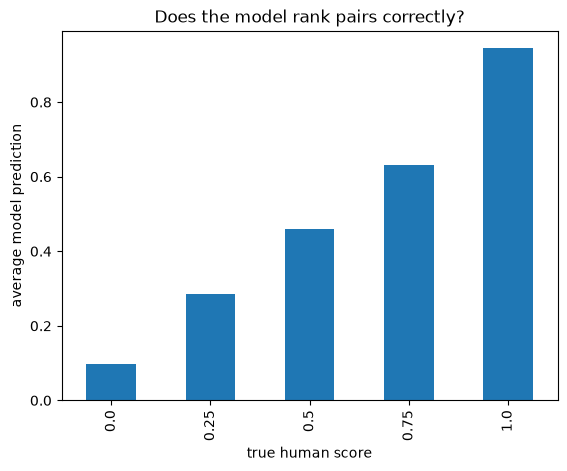

In [30]:
import matplotlib.pyplot as plt

# Average prediction for each true score. A good model gives a staircase going up from left to right.
look.groupby('score').pred.mean().plot(kind='bar')
plt.xlabel('true human score'); plt.ylabel('average model prediction'); plt.title('Does the model rank pairs correctly?')
plt.show()

## 9. Predict the test set

Finally the real task: predict scores for the rows in `test.csv`. We reuse the same tokenizer function, then clip. We also save a `submission.csv` in the format Kaggle expects (an `id` and a `score` per row).

*Note:* this competition is a **code competition**, so Kaggle only scores a submission made from a notebook running on Kaggle itself. The file below shows the correct format and lets us check the predictions here.

In [31]:
tst_ds = Dataset.from_pandas(tst_df[['input']]).map(tok_func, batched=True)   # tokenize the test text exactly like the training text
tst_preds = trainer.predict(tst_ds).predictions.flatten()                    # model predictions for the test rows
tst_preds = np.clip(tst_preds, 0, 1)                                         # keep them in the valid range

sub = pd.DataFrame({'id': tst_df.id, 'score': tst_preds})   # the format Kaggle expects
sub.to_csv('us-patent-submission.csv', index=False)         # save it next to the notebook (git-ignored)
sub.head()

Map: 100%|██████████| 36/36 [00:00<00:00, 1797.07 examples/s]


,id,score
0,4112d61851461f60,0.49
1,09e418c93a776564,0.79
2,36baf228038e314b,0.52
3,1f37ead645e7f0c8,0.32
4,71a5b6ad068d531f,0.39


In [32]:
# Sanity check: read each test row next to its prediction
tst_df.assign(pred=tst_preds)[['anchor', 'target', 'context', 'pred']].head(8)

,anchor,target,context,pred
0,opc drum,inorganic photoconductor drum,G02,0.49
1,adjust gas flow,altering gas flow,F23,0.79
2,lower trunnion,lower locating,B60,0.52
3,cap component,upper portion,D06,0.32
4,neural stimulation,artificial neural network,H04,0.39
5,dry corn,dry corn starch,C12,0.54
6,tunneling capacitor,capacitor housing,G11,0.48
7,angular contact bearing,contact therapy radiation,B23,0.00


## 10. Summary

### What we did

| Step | What | Where it fits |
|---|---|---|
| 1 | Looked at the data: 36k pairs, 733 anchors, scores in 5 steps | same habit as Titanic |
| 2 | Glued three columns into one sentence | turning any problem into text |
| 3 | Tokenized with DeBERTa's own subword tokenizer | text → numbers |
| 4 | Split **by anchor** so validation measures unseen anchors | avoiding leakage |
| 5 | Chose **Pearson correlation** and a word-overlap baseline | right metric for scores |
| 6 | Fine-tuned DeBERTa with `Trainer` | transfer learning |
| 7 | Clipped predictions to 0 to 1 and predicted the test set | finishing touches |

### Key lessons
- **Pretrained model + small dataset = strong result.** We did not teach English. We only adapted a model that already knew it.
- **Tokenizer and model must match.** Always load both from the same model name.
- **How you split matters as much as the model.** A random row split would have looked better and meant less.
- **Beat a simple baseline first.** It tells you how much the heavy model really adds.
- **The `Trainer` is the loop you already know.** Forward, loss, backward, step, zero the gradients, plus conveniences.

### Connection to RAG and search
A search system first finds candidate documents quickly with embeddings, then uses a **cross-encoder** to re-score the best few by reading the query and the document *together*. What you built is a cross-encoder: input = two texts, output = one relevance score. Swap "patent phrases" for "user question and a document chunk" and you have a reranker.

### Ideas to try next
- Change `model_nm` to `microsoft/deberta-v3-base` (bigger, stronger; lower `bs` to 16 to 32 for 6 GB of memory).
- Try more epochs, or a different learning rate, and watch the validation score.
- Train several models with different seeds and average their predictions (an *ensemble*), as you did with fastai on Titanic.
- Look at the biggest errors above and ask: is the model wrong, or is the human label debatable?